In [2]:
# Laura Beltrán - Emisiones globales de CO2 procedentes de los combustibles fósiles
# Parte 1 - Proyecto Emisiones de CO2 Grupo I

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

print("Librerías listas")

Librerías listas


In [3]:
# 1. Descargar y cargar los datos de Our World in Data
url = "https://nyc3.digitaloceanspaces.com/owid-public/data/co2/owid-co2-data.csv"

df = pd.read_csv(url)
print("Datos cargados")
print(df.shape)
df.head()

Datos cargados
(50191, 79)


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# 2. LIMPIEZA - Solo nos quedamos con el MUNDO

# Filtrar solo World (emisiones globales)
mundo = df[df['country'] == 'World'].copy()

# Nos quedamos solo con las columnas que nos sirven para tu tema
# co2 = CO2 de combustibles fósiles
# coal_co2, oil_co2, gas_co2 = de dónde viene ese CO2
mundo = mundo[['year', 'co2', 'coal_co2', 'oil_co2', 'gas_co2', 'cement_co2']]

# Quitar filas donde no hay dato de co2
mundo = mundo.dropna(subset=['co2'])

# Ver cómo quedó
print("Filas que quedaron:", len(mundo))
print("Primeros años:", mundo['year'].min(), "a", mundo['year'].max())
mundo.head(10)

Filas que quedaron: 274
Primeros años: 1750 a 2023


,year,co2,coal_co2,oil_co2,gas_co2,cement_co2
49295,1750,9.306,9.306,NaN,NaN,NaN
49296,1751,9.407,9.407,NaN,NaN,NaN
49297,1752,9.505,9.505,NaN,NaN,NaN
49298,1753,9.610,9.610,NaN,NaN,NaN
49299,1754,9.734,9.734,NaN,NaN,NaN
49300,1755,9.793,9.793,NaN,NaN,NaN
49301,1756,9.910,9.910,NaN,NaN,NaN
49302,1757,10.094,10.094,NaN,NaN,NaN
49303,1758,10.216,10.216,NaN,NaN,NaN
49304,1759,10.339,10.339,NaN,NaN,NaN


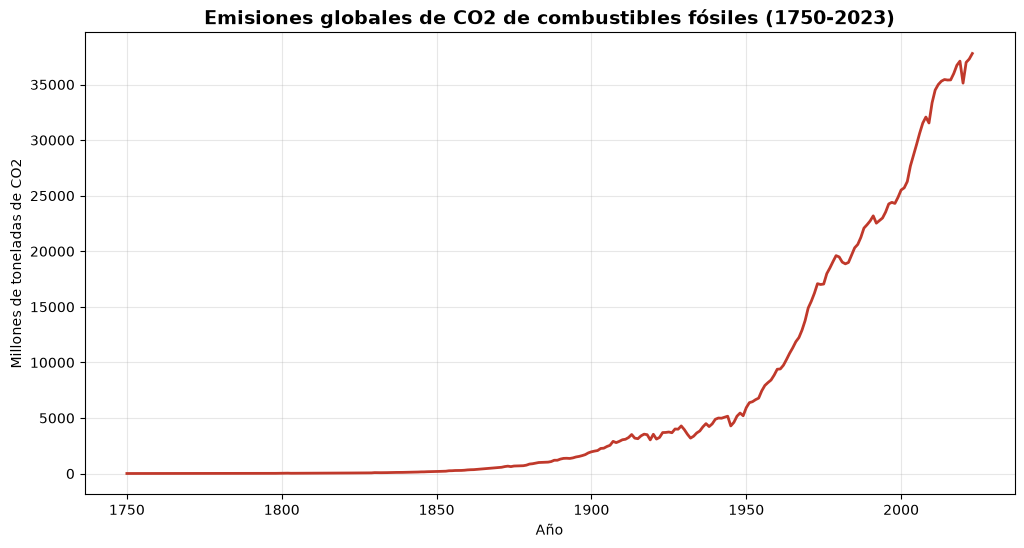

En 1750 emitíamos: 9.306 millones de toneladas
En 2023 emitimos: 37791.57 millones de toneladas


In [5]:
# 3. VISUALIZACIÓN - ¿Cómo ha subido el CO2 en el mundo?

plt.figure(figsize=(12, 6))
plt.plot(mundo['year'], mundo['co2'], color='#C0392B', linewidth=2)
plt.title('Emisiones globales de CO2 de combustibles fósiles (1750-2023)', fontsize=14, weight='bold')
plt.xlabel('Año')
plt.ylabel('Millones de toneladas de CO2')
plt.grid(True, alpha=0.3)
plt.show()

# Dato curioso para tu interpretación
print("En 1750 emitíamos:", mundo.iloc[0]['co2'], "millones de toneladas")
print("En 2023 emitimos:", mundo.iloc[-1]['co2'], "millones de toneladas")

El modelo explica el 98.68 % de lo que pasó

Predicción:
En 2030 emitiríamos 40954.0 millones de toneladas
En 2040 emitiríamos 45440.0 millones de toneladas
En 2050 emitiríamos 49926.0 millones de toneladas


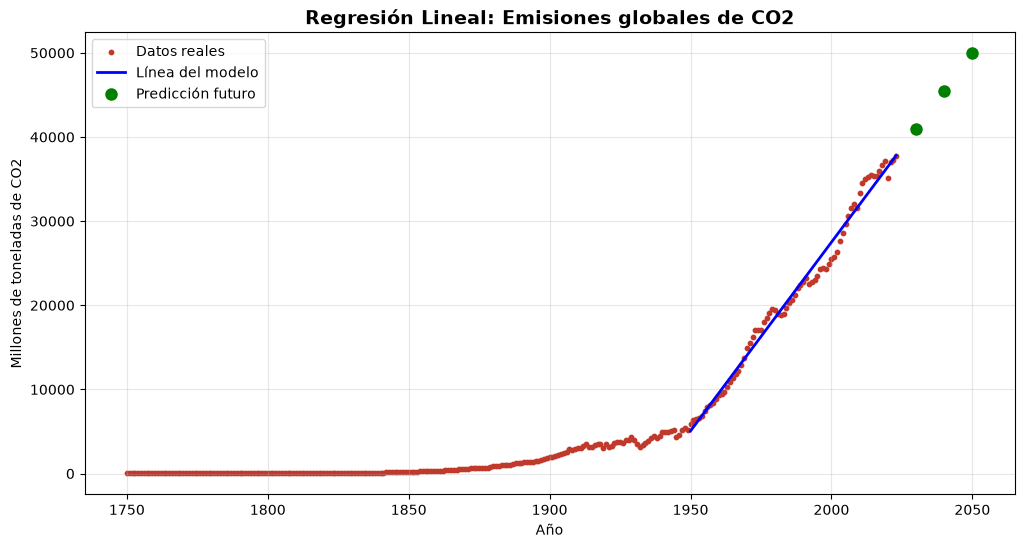

In [6]:
# 4. MODELO - Regresión Lineal para predecir el futuro

# Usamos solo desde 1950 porque antes era casi plano y confundiría al modelo
datos_modelo = mundo[mundo['year'] >= 1950].copy()

X = datos_modelo[['year']]  # Lo que conocemos: el año
y = datos_modelo['co2']     # Lo que queremos predecir: el CO2

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# ¿Qué tan bien le atinó el modelo?
prediccion = modelo.predict(X)
r2 = r2_score(y, prediccion)
print("El modelo explica el", round(r2*100, 2), "% de lo que pasó")

# Predecir el futuro
futuro = pd.DataFrame({'year': [2030, 2040, 2050]})
pred_futuro = modelo.predict(futuro)
print("\nPredicción:")
for año, valor in zip(futuro['year'], pred_futuro):
    print(f"En {año} emitiríamos {round(valor, 0)} millones de toneladas")

# Gráfica con la línea del modelo
plt.figure(figsize=(12, 6))
plt.scatter(mundo['year'], mundo['co2'], s=10, color='#C0392B', label='Datos reales')
plt.plot(datos_modelo['year'], prediccion, color='blue', linewidth=2, label='Línea del modelo')
plt.plot(futuro['year'], pred_futuro, 'o', color='green', markersize=8, label='Predicción futuro')
plt.title('Regresión Lineal: Emisiones globales de CO2', fontsize=14, weight='bold')
plt.xlabel('Año')
plt.ylabel('Millones de toneladas de CO2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5. INTERPRETACIÓN - ¿Qué significa todo esto?

En 1750 el mundo emitía solo 9.3 millones de toneladas de CO2 y en 2023 ya íbamos en más de 37.000 millones. 
O sea, multiplicamos las emisiones por casi 4.000 veces.

El crecimiento fue lento hasta 1950 y después se disparó con la industrialización, el uso del petróleo, el gas y el carbón para producir electricidad, transporte y fábricas.

Mi modelo de regresión lineal explica el 98.68% de lo que pasó, lo que significa que es muy confiable para ver la tendencia.
Si seguimos como vamos, sin cambiar nada, en 2050 emitiríamos casi 50.000 millones de toneladas.

Esto es preocupante porque, como dice el artículo de Our World in Data, los combustibles fósiles son la principal causa del cambio climático. 
La conclusión es que no podemos seguir con la misma tendencia, necesitamos cambiar a energías limpias para que esa línea deje de subir.